# Controlled missingness on real survival data

Real patients, real features and real survival times; only the gaps are made by us, so we know exactly how they arose.

- **GBSG2** (686 breast cancer patients) and **WHAS500** (500 heart attack patients) have no missing values. We remove 30% of the continuous measurements (GBSG2: `estrec`, `progrec`, `pnodes`, `tsize`; WHAS500: `bmi`, `diasbp`, `hr`, `sysbp`). Age is always observed.
- **FLChain** has real missing values (creatinine, 17% of people), which are related to the outcome.

Mechanisms:
- **MCAR**: at random
- **MAR**: depends on age (always observed)
- **MNAR**: larger values are more likely to be missing
- **risk**: depends on how sick the patient is *at baseline* (linear predictor of a Cox model on the complete data). High-risk patients miss some measurements, low-risk patients others. This is the realistic version of the survival-dependent missingness in notebook 06: the decision is made at admission, not by the future survival time.

WHAS500's `los` (length of hospital stay) is dropped: it is recorded after admission, and for the 40 patients who died in hospital it equals their survival time.

Each setting is repeated with 5 seeds (data split, removed values and model initialisation change together). Full run: about 1.5 h on a CPU. `QUICK = True` for a short check.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src.baselines import run_cox
from src.data import load_sksurv
from src.missing import MissVaDeSC, fill_and_mask, load_real_with_missingness
from src.vadesc import evaluate_vadesc, train_vadesc

QUICK = False
SEEDS = [0, 1] if QUICK else [0, 1, 2, 3, 4]
EPOCHS = 60 if QUICK else 300
MECHANISMS = ["none", "MCAR", "MAR", "MNAR", "risk"]
METHODS = ["Cox (mean imp.)", "Cox (+mask)", "VaDeSC (mean imp.)", "VaDeSC (+mask input)",
           "MissVaDeSC", "MissVaDeSC + mask model"]

## 1. Is the removed data informative?

Event rate of patients whose value is missing vs. observed, per removed feature (seed 0, training split).

In [2]:
from src.missing import REAL_MISSING_COLS
rows = []
for name in ["GBSG2", "WHAS500"]:
    for mech in MECHANISMS[1:]:
        d = load_real_with_missingness(name, mech, seed=0)
        X = pd.DataFrame(d.X_tr, columns=d.features)
        for c in REAL_MISSING_COLS[name]:
            m = X[c].isna().to_numpy()
            rows.append({"dataset": name, "mechanism": mech, "feature": c, "missing": m.mean(),
                         "event rate if missing": d.e_tr[m].mean(), "if observed": d.e_tr[~m].mean()})
pd.DataFrame(rows).set_index(["dataset", "mechanism", "feature"]).round(2).unstack("feature")

missing                                                 \
feature               bmi diasbp estrec    hr pnodes progrec sysbp tsize   
dataset mechanism                                                          
GBSG2   MAR           NaN    NaN   0.30   NaN   0.32    0.30   NaN  0.29   
        MCAR          NaN    NaN   0.27   NaN   0.34    0.33   NaN  0.29   
        MNAR          NaN    NaN   0.28   NaN   0.34    0.34   NaN  0.31   
        risk          NaN    NaN   0.30   NaN   0.32    0.32   NaN  0.29   
WHAS500 MAR          0.28   0.30    NaN  0.32    NaN     NaN  0.31   NaN   
        MCAR         0.24   0.29    NaN  0.29    NaN     NaN  0.35   NaN   
        MNAR         0.29   0.31    NaN  0.31    NaN     NaN  0.32   NaN   
        risk         0.27   0.28    NaN  0.29    NaN     NaN  0.36   NaN   

                  event rate if missing         ...             if observed  \
feature                             bmi diasbp  ... sysbp tsize         bmi   
dataset mechanism                               ...                           
GBSG2   MAR                         NaN    NaN  ...   NaN  0.45         NaN   
        MCAR                        NaN    NaN  ...   NaN  0.45         NaN   
        MNAR                        NaN    NaN  ...   NaN  0.47         NaN   
        risk                        NaN    NaN  ...   NaN  0.30         NaN   
WHAS500 MAR                        0.61   0.64  ...  0.64   NaN        0.36   
        MCAR                       0.42   0.39  ...  0.46   NaN        0.43   
        MNAR                       0.32   0.33  ...  0.40   NaN        0.48   
        risk                       0.71   0.69  ...  0.20   NaN        0.33   

                                                                  
feature           diasbp estrec    hr pnodes progrec sysbp tsize  
dataset mechanism                                                 
GBSG2   MAR          NaN   0.45   NaN   0.43    0.46   NaN  0.43  
        MCAR         NaN   0.46   NaN   0.44    0.48   NaN  0.43  
        MNAR         NaN   0.46   NaN   0.37    0.49   NaN  0.42  
        risk         NaN   0.39   NaN   0.50    0.39   NaN  0.49  
WHAS500 MAR         0.34    NaN  0.34    NaN     NaN  0.34   NaN  
        MCAR        0.45    NaN  0.43    NaN     NaN  0.41   NaN  
        MNAR        0.48    NaN  0.40    NaN     NaN  0.45   NaN  
        risk        0.33    NaN  0.53    NaN     NaN  0.56   NaN  

[8 rows x 24 columns]

## 2. Methods

Same models as notebook 06: Cox and VaDeSC with mean imputation, both with the mask as extra features, and the missingness-aware VaDeSC with and without a decoder for the mask, $p(m \mid z)$. Small datasets, so VaDeSC uses the paper's FLChain configuration (`K=2`, `latent_dim=4`, Weibull shape 1).

In [3]:
def run_all(ds, seed, K=2, d_lat=4, weibull_k=1.0, epochs=EPOCHS):
    d0, d1 = fill_and_mask(ds, False), fill_and_mask(ds, True)
    out = [{"method": "Cox (mean imp.)", **run_cox(d0)}, {"method": "Cox (+mask)", **run_cox(d1)}]
    for name, d, kw in [("VaDeSC (mean imp.)", d0, {}),
                        ("VaDeSC (+mask input)", d1, {}),
                        ("MissVaDeSC", d1, {"model_cls": MissVaDeSC, "model_kwargs": {"model_mask": False}}),
                        ("MissVaDeSC + mask model", d1, {"model_cls": MissVaDeSC, "model_kwargs": {"model_mask": True}})]:
        m, _, _ = evaluate_vadesc(train_vadesc(d, K=K, d_lat=d_lat, weibull_k=weibull_k, epochs=epochs, seed=seed, **kw), d)
        out.append({"method": name, "C-index": m["C-index"], "IBS": m["IBS"]})
    return out

rows = []
for name in ["GBSG2", "WHAS500"]:
    for mech in MECHANISMS:
        for seed in SEEDS:
            ds = load_real_with_missingness(name, mech, seed=seed)
            for r in run_all(ds, seed):
                rows.append({"dataset": name, "mechanism": mech, "seed": seed, **r})
        print(name, mech, "done", flush=True)
res = pd.DataFrame(rows)

GBSG2 none done


GBSG2 MCAR done


GBSG2 MAR done


GBSG2 MNAR done


GBSG2 risk done


WHAS500 none done


WHAS500 MCAR done


WHAS500 MAR done


WHAS500 MNAR done


WHAS500 risk done


## 3. Results

In [4]:
summary = res.groupby(["dataset", "method", "mechanism"])["C-index"].agg(["mean", "std"])
table = summary["mean"].round(3).astype(str) + " ± " + summary["std"].round(3).astype(str)
table.unstack("mechanism")[MECHANISMS].reindex(METHODS, level=1)

mechanism                                 none           MCAR            MAR  \
dataset method                                                                 
GBSG2   Cox (mean imp.)          0.644 ± 0.022  0.608 ± 0.021  0.613 ± 0.021   
        Cox (+mask)              0.644 ± 0.022  0.596 ± 0.013   0.61 ± 0.024   
        VaDeSC (mean imp.)       0.649 ± 0.015  0.608 ± 0.027  0.622 ± 0.035   
        VaDeSC (+mask input)     0.645 ± 0.035  0.588 ± 0.044  0.599 ± 0.029   
        MissVaDeSC               0.652 ± 0.019  0.623 ± 0.037  0.621 ± 0.024   
        MissVaDeSC + mask model  0.644 ± 0.011  0.616 ± 0.028   0.62 ± 0.031   
WHAS500 Cox (mean imp.)          0.765 ± 0.026   0.755 ± 0.03   0.756 ± 0.03   
        Cox (+mask)              0.765 ± 0.026  0.747 ± 0.036  0.747 ± 0.039   
        VaDeSC (mean imp.)       0.738 ± 0.035  0.751 ± 0.014  0.726 ± 0.033   
        VaDeSC (+mask input)     0.745 ± 0.027  0.755 ± 0.007   0.74 ± 0.013   
        MissVaDeSC               0.755 ± 0.019  0.743 ± 0.024  0.742 ± 0.019   
        MissVaDeSC + mask model  0.748 ± 0.022  0.738 ± 0.026  0.745 ± 0.026   

mechanism                                 MNAR           risk  
dataset method                                                 
GBSG2   Cox (mean imp.)          0.619 ± 0.035  0.622 ± 0.011  
        Cox (+mask)              0.627 ± 0.017  0.625 ± 0.012  
        VaDeSC (mean imp.)       0.623 ± 0.028  0.614 ± 0.016  
        VaDeSC (+mask input)      0.601 ± 0.05   0.61 ± 0.057  
        MissVaDeSC               0.635 ± 0.023   0.59 ± 0.051  
        MissVaDeSC + mask model  0.636 ± 0.015  0.638 ± 0.013  
WHAS500 Cox (mean imp.)          0.748 ± 0.021  0.751 ± 0.039  
        Cox (+mask)               0.76 ± 0.028  0.752 ± 0.041  
        VaDeSC (mean imp.)        0.73 ± 0.008  0.727 ± 0.028  
        VaDeSC (+mask input)     0.723 ± 0.064  0.745 ± 0.027  
        MissVaDeSC               0.742 ± 0.026  0.741 ± 0.029  
        MissVaDeSC + mask model  0.744 ± 0.018  0.755 ± 0.025

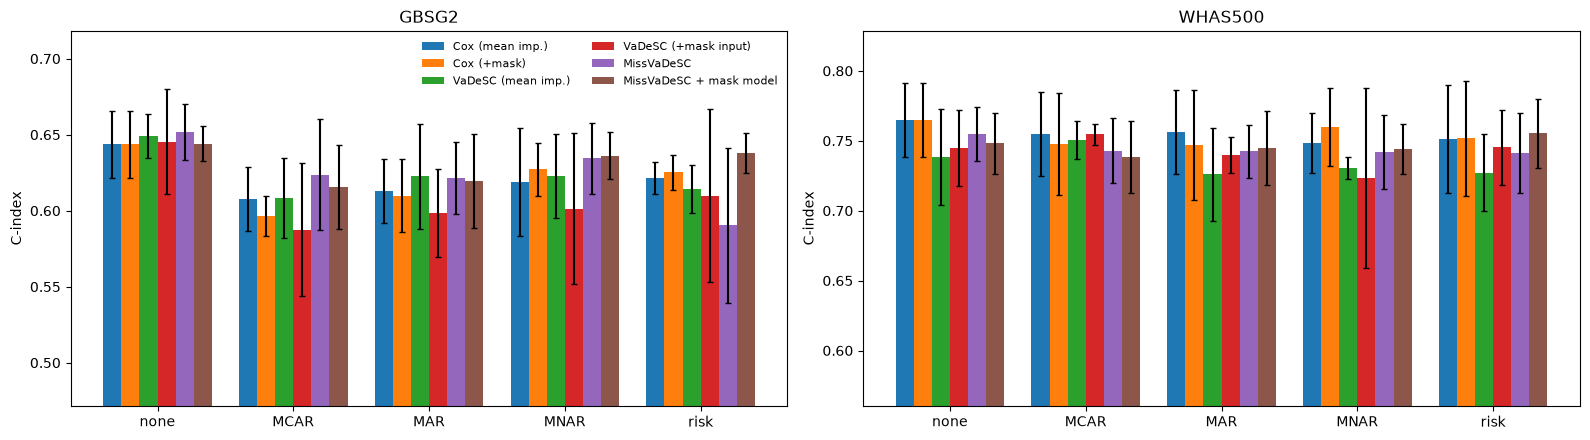

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=False)
for ax, name in zip(axes, ["GBSG2", "WHAS500"]):
    sub = res[res.dataset == name]
    w = 0.8 / len(METHODS)
    for i, m in enumerate(METHODS):
        g = sub[sub.method == m].groupby("mechanism")["C-index"]
        ax.bar(np.arange(len(MECHANISMS)) + i * w, g.mean().reindex(MECHANISMS), w,
               yerr=g.std().reindex(MECHANISMS), capsize=2, label=m)
    ax.set_xticks(np.arange(len(MECHANISMS)) + 0.4 - w / 2, MECHANISMS)
    ax.set(title=name, ylabel="C-index", ylim=(sub["C-index"].min() - 0.05, sub["C-index"].max() + 0.03))
axes[0].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

Paired differences against VaDeSC with mean imputation (same dataset, mechanism and seed). The 95% CI uses the 5 seeds.

In [6]:
def paired(res, ref="VaDeSC (mean imp.)"):
    out = []
    for (name, mech), sub in res.groupby(["dataset", "mechanism"]):
        p = sub.pivot_table(index="seed", columns="method", values="C-index")
        for m in METHODS:
            if m == ref:
                continue
            diff = p[m] - p[ref]
            n = len(diff)
            half = stats.t.ppf(0.975, n - 1) * diff.std(ddof=1) / np.sqrt(n)
            out.append({"dataset": name, "mechanism": mech, "method": m, "mean diff": diff.mean(),
                        "95% CI": f"[{diff.mean() - half:+.3f}, {diff.mean() + half:+.3f}]"})
    return pd.DataFrame(out).set_index(["dataset", "mechanism", "method"])

paired(res).round(3)

mean diff            95% CI
dataset mechanism method                                              
GBSG2   MAR       Cox (mean imp.)             -0.010  [-0.047, +0.028]
                  Cox (+mask)                 -0.013  [-0.051, +0.026]
                  VaDeSC (+mask input)        -0.024  [-0.067, +0.019]
                  MissVaDeSC                  -0.001  [-0.017, +0.015]
                  MissVaDeSC + mask model     -0.003  [-0.022, +0.017]
        MCAR      Cox (mean imp.)             -0.001  [-0.024, +0.023]
                  Cox (+mask)                 -0.012  [-0.046, +0.022]
                  VaDeSC (+mask input)        -0.021  [-0.083, +0.041]
                  MissVaDeSC                   0.015  [-0.007, +0.038]
                  MissVaDeSC + mask model      0.008  [-0.025, +0.040]
        MNAR      Cox (mean imp.)             -0.004  [-0.030, +0.023]
                  Cox (+mask)                  0.005  [-0.011, +0.020]
                  VaDeSC (+mask input)        -0.021  [-0.060, +0.017]
                  MissVaDeSC                   0.012  [-0.003, +0.026]
                  MissVaDeSC + mask model      0.014  [-0.017, +0.045]
        none      Cox (mean imp.)             -0.005  [-0.031, +0.020]
                  Cox (+mask)                 -0.005  [-0.031, +0.020]
                  VaDeSC (+mask input)        -0.004  [-0.060, +0.052]
                  MissVaDeSC                   0.003  [-0.011, +0.017]
                  MissVaDeSC + mask model     -0.005  [-0.023, +0.013]
        risk      Cox (mean imp.)              0.007  [-0.023, +0.038]
                  Cox (+mask)                  0.011  [-0.017, +0.039]
                  VaDeSC (+mask input)        -0.004  [-0.073, +0.065]
                  MissVaDeSC                  -0.024  [-0.087, +0.039]
                  MissVaDeSC + mask model      0.024  [-0.006, +0.054]
WHAS500 MAR       Cox (mean imp.)              0.030  [+0.004, +0.056]
                  Cox (+mask)                  0.021  [-0.004, +0.046]
                  VaDeSC (+mask input)         0.014  [-0.031, +0.058]
                  MissVaDeSC                   0.016  [-0.021, +0.054]
                  MissVaDeSC + mask model      0.019  [-0.007, +0.044]
        MCAR      Cox (mean imp.)              0.004  [-0.018, +0.027]
                  Cox (+mask)                 -0.003  [-0.035, +0.029]
                  VaDeSC (+mask input)         0.004  [-0.016, +0.024]
                  MissVaDeSC                  -0.008  [-0.037, +0.022]
                  MissVaDeSC + mask model     -0.012  [-0.047, +0.022]
        MNAR      Cox (mean imp.)              0.018  [-0.007, +0.042]
                  Cox (+mask)                  0.029  [-0.005, +0.064]
                  VaDeSC (+mask input)        -0.007  [-0.078, +0.064]
                  MissVaDeSC                   0.011  [-0.027, +0.050]
                  MissVaDeSC + mask model      0.014  [-0.011, +0.038]
        none      Cox (mean imp.)              0.026  [-0.012, +0.065]
                  Cox (+mask)                  0.026  [-0.012, +0.065]
                  VaDeSC (+mask input)         0.007  [-0.060, +0.073]
                  MissVaDeSC                   0.017  [-0.023, +0.056]
                  MissVaDeSC + mask model      0.010  [-0.020, +0.039]
        risk      Cox (mean imp.)              0.024  [+0.009, +0.039]
                  Cox (+mask)                  0.025  [+0.003, +0.046]
                  VaDeSC (+mask input)         0.018  [-0.036, +0.072]
                  MissVaDeSC                   0.014  [-0.001, +0.030]
                  MissVaDeSC + mask model      0.028  [+0.007, +0.049]

## 4. Real missingness: FLChain

Creatinine is missing for 17% of people, and those people died less often (15% vs. 30%), so here the missingness itself is informative. No values are removed by us.

In [7]:
rows = []
for seed in SEEDS:
    ds = load_sksurv("FLChain", seed=seed, keep_missing=True)
    for r in run_all(ds, seed):
        rows.append({"seed": seed, **r})
fl = pd.DataFrame(rows)
fl.groupby("method")[["C-index", "IBS"]].agg(["mean", "std"]).reindex(METHODS).round(3)

C-index           IBS       
                           mean    std   mean    std
method                                              
Cox (mean imp.)           0.792  0.007  0.108  0.002
Cox (+mask)               0.793  0.007  0.108  0.002
VaDeSC (mean imp.)        0.793  0.008  0.110  0.002
VaDeSC (+mask input)      0.791  0.009  0.110  0.002
MissVaDeSC                0.792  0.008  0.110  0.002
MissVaDeSC + mask model   0.793  0.009  0.110  0.002

## Notes

- Missingness is decided per value with the probabilities above; the overall rate in the selected columns is about 30% for every mechanism.
- The `risk` mechanism uses a Cox model fitted on the complete data, only to decide which values to remove. The models never see it.
- With 500-700 patients the test sets are small (100-140 patients), so differences of a few hundredths are within the noise; the paired comparison and the CIs account for that.